<a href="https://colab.research.google.com/github/elbuh0/genai-course/blob/main/genai-course/week4/homework/Week_4_HW_SDXL_ControlNet.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 4 Homework — SDXL Pipeline, ControlNet & Evaluation
**COM SCI-X 455 · Week 4 · Megan Armani, PhD**

> Push to `genai-course/week4/`  |  GPU: T4 or A10G required

---

## Setup

In [ ]:
!pip install diffusers transformers accelerate xformers torch --quiet

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 46.3 MB/s eta 0:00:00


In [ ]:
import torch
from diffusers import (StableDiffusionXLPipeline, DPMSolverMultistepScheduler,
                        StableDiffusionXLControlNetPipeline, ControlNetModel,
                        DDIMScheduler)
from PIL import Image
import numpy as np, matplotlib.pyplot as plt, time

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print("Device:", DEVICE)
print("VRAM:", torch.cuda.get_device_properties(0).total_memory/1e9, "GB" if DEVICE=='cuda' else "N/A")

Device: cuda
VRAM: 15.637086208 GB


## Part 1 — Multi-Domain Text-to-Image with SDXL

In [ ]:
pipe = StableDiffusionXLPipeline.from_pretrained(
    "stabilityai/stable-diffusion-xl-base-1.0",
    torch_dtype=torch.float16, use_safetensors=True
).to(DEVICE)
pipe.scheduler = DPMSolverMultistepScheduler.from_config(pipe.scheduler.config)
print("SDXL loaded")

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/517 [00:00<?, ?it/s]

SDXL loaded


/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


model_index.json:   0%|          | 0.00/609 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 19 files:   0%|          | 0/19 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

...

There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.


Architecture/Interiors: Mid-century interior | specific  | Euler    |  18.0s


  0%|          | 0/30 [00:00<?, ?it/s]

There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.


Architecture/Interiors: Mid-century interior | technical | Euler    |  18.0s


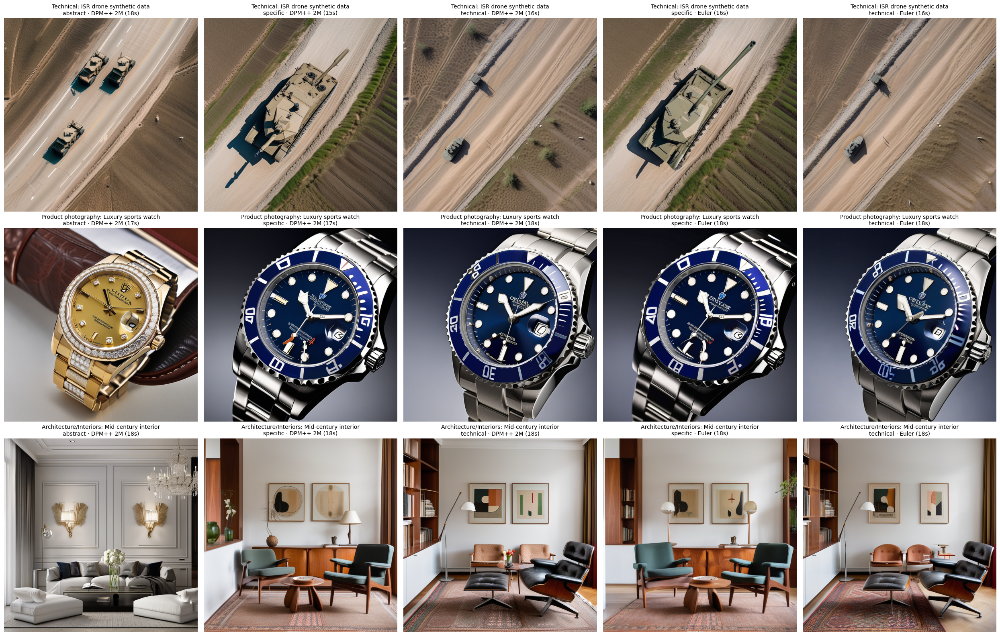

In [ ]:

# 15 images: 3 domains x 5 runs (3 prompt levels x DPM++ 2M, + 2 levels x Euler), same seed throughout
import os, time, torch
import matplotlib.pyplot as plt
from diffusers import StableDiffusionXLPipeline, DPMSolverMultistepScheduler, EulerDiscreteScheduler

DEVICE, SEED, STEPS, CFG, SIZE = "cuda", 42, 30, 7.0, 768
OUT = "sdxl_domains"; os.makedirs(OUT, exist_ok=True)

# Reuse loaded SDXL if present (avoid a 2nd copy/OOM on T4)
if "pipe" not in globals():
    pipe = StableDiffusionXLPipeline.from_pretrained(
        "stabilityai/stable-diffusion-xl-base-1.0",
        torch_dtype=torch.float16, variant="fp16", use_safetensors=True,
    ).to(DEVICE)
base_cfg = pipe.scheduler.config

SCHEDULERS = {
    "DPM++ 2M": lambda: DPMSolverMultistepScheduler.from_config(base_cfg, algorithm_type="dpmsolver++", solver_order=2),
    "Euler":    lambda: EulerDiscreteScheduler.from_config(base_cfg),
}

DOMAINS = {
    "Technical: ISR drone synthetic data": {
        "abstract": "military vehicle seen from a drone",
        "specific": "aerial drone photo of a main battle tank parked beside an earthen revetment in a rural field, overcast",
        "technical": ("nadir overhead electro-optical imagery from a small UAS at 120 m altitude, T-90 main battle tank with anti-drone caging and "
                      "BMP-1 tracked armored personnel carrier beside an earthen revetment, partial camouflage netting, "
                      "approx 10 cm ground sample distance, flat midday light, slight motion blur, sensor noise, "
                      "realistic surveillance imagery"),
        "negative": "cartoon, illustration, video game render, toy, text, watermark, people, oversaturated",
    },
    "Product photography: Luxury sports watch": {
        "abstract": "a luxury watch",
        "specific": "product photo of a Swiss luxury stainless-steel dive watch with a forest green dial on dark slate",
        "technical": ("studio product photography, Swiss luxury stainless-steel dive watch, deep green wave-textured dial, "
                      "brushed and polished bracelet, clean Rolex Datejust or Omega Seamaster composition,"
                      "focus-stacked, e-commerce catalog quality"),
        "negative": "text, logo, watermark, distorted numerals, extra hands, blurry, cartoon, plastic look, ceramic bezel",
    },
    "Architecture/Interiors: Mid-century interior": {
        "abstract": "a stylish living room",
        "specific": "Central European mid-century modern living room with a sculptural bentwood armchair, teak sideboard and wool rug",
        "technical": ("architectural interior photography, 1960s Central European mid-century living room in a Vienna "
                      "apartment, Herman Miller lounge chair, walnut sideboard, Hungarian geometric wool rug, "
                      "chrome multi-head floor lamp, herringbone parquet, soft north-facing window light,"
                      "eye-level, natural color grading, magazine editorial, art heirloom quality pieces"),
        "negative": "clutter, warped lines, distorted furniture, cartoon, low quality, watermark, oversaturated",
    },
}

RUNS = [("abstract", "DPM++ 2M"), ("specific", "DPM++ 2M"), ("technical", "DPM++ 2M"),
        ("specific", "Euler"), ("technical", "Euler")]

results = []
for domain, p in DOMAINS.items():
    for level, sched_name in RUNS:
        pipe.scheduler = SCHEDULERS[sched_name]()
        t0 = time.time()
        img = pipe(
            prompt=p[level], negative_prompt=p["negative"],
            guidance_scale=CFG, num_inference_steps=STEPS, height=SIZE, width=SIZE,
            generator=torch.Generator(DEVICE).manual_seed(SEED),   # same seed everywhere
        ).images[0]
        dt = time.time() - t0
        fname = f"{OUT}/{domain[:3].lower()}_{level}_{sched_name.replace(' ', '').replace('+', 'p')}.png"
        img.save(fname)
        results.append({"domain": domain, "level": level, "sched": sched_name, "img": img, "time": dt})
        print(f"{domain:22s} | {level:9s} | {sched_name:8s} | {dt:5.1f}s")

pipe.scheduler = SCHEDULERS["DPM++ 2M"]()   # restore default

# 3x5 grid: rows = domains, cols = runs
fig, axes = plt.subplots(3, 5, figsize=(25, 16))
for ax, r in zip(axes.flat, results):
    ax.imshow(r["img"])
    ax.set_title(f"{r['domain']}\n{r['level']} · {r['sched']} ({r['time']:.0f}s)", fontsize=10)
    ax.axis("off")
plt.tight_layout()
plt.savefig(f"{OUT}/grid_3x5.png", dpi=100)
plt.show()

## Part 2 — ControlNet Application to a Real Use Case

In [ ]:
from google.colab import files
up = files.upload()
sketch_path = next(iter(up))
print("Sketch:", sketch_path)

Saving spawn.jpg to spawn (7).jpg
Sketch: spawn (7).jpg


GPU in use before loading: 0.0 GB


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_validators.py:206: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(
An error occurred while trying to fetch thibaud/controlnet-openpose-sdxl-1.0: thibaud/controlnet-openpose-sdxl-1.0 does not appear to have a file named diffusion_pytorch_model.safetensors.
Defaulting to unsafe serialization. Pass `allow_pickle=False` to raise an error instead.
/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/517 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

...

There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.


crouching     25.2s


  0%|          | 0/30 [00:00<?, ?it/s]

There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.


pointing      25.2s


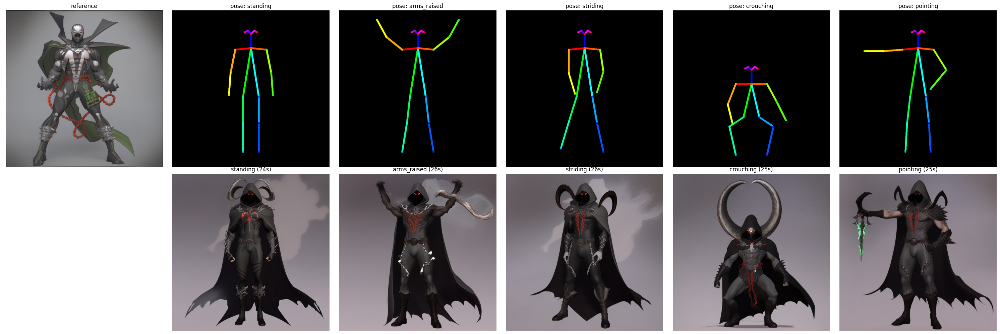

In [ ]:
# Same character (from uploaded reference), 5 poses: OpenPose ControlNet + IP-Adapter + fixed seed
import os, gc, time, torch, numpy as np, cv2
from PIL import Image
import matplotlib.pyplot as plt
from diffusers import StableDiffusionXLControlNetPipeline, ControlNetModel, DPMSolverMultistepScheduler

DEVICE, SEED, STEPS, CFG, SIZE = "cuda", 42, 30, 7.0, 768
CN_SCALE = 0.9        # pose adherence
IP_SCALE = 0.6        # how strongly the reference image shapes appearance (0.4-0.8)
REF_PATH = "character_styles/3d.png"   # or: sketch_path (raw upload)
OUT = "character_poses_ref"; os.makedirs(OUT, exist_ok=True)

CHARACTER = (CHARACTER = ("muscular hellspawn, black suit with white markings, "
             "skeletal pale face, glowing green eyes, sharp teeth, "
             "tattered crimson cape, thick metal chains, spiked gauntlets, "
             "armored boots, demonic silhouette, supernatural shadows")
STYLE = "full-body, dark gothic fantasy illustration, dramatic rim lighting, smoky dark background"
NEG = ("multiple people, extra limbs, extra arms, extra fingers, deformed hands, cropped, "
       "text, watermark, blurry, bright cheerful colors")
PROMPT = f"{STYLE}, {CHARACTER}"

for n in ["pipe", "pipe_cc", "pipe_cn", "controlnet", "pipe_turbo", "pipe_ddim"]:
    globals().pop(n, None)
gc.collect(); torch.cuda.empty_cache()
print(f"GPU in use before loading: {torch.cuda.memory_allocated()/1e9:.1f} GB")   # must be 0.0

# SDXL + OpenPose ControlNet
controlnet = ControlNetModel.from_pretrained("thibaud/controlnet-openpose-sdxl-1.0", torch_dtype=torch.float16)
pipe_cc = StableDiffusionXLControlNetPipeline.from_pretrained(
    "stabilityai/stable-diffusion-xl-base-1.0",
    controlnet=controlnet, torch_dtype=torch.float16, variant="fp16", use_safetensors=True,
)
# Reference image becomes an image prompt (ViT-H encoder smaller option)
pipe_cc.load_ip_adapter("h94/IP-Adapter", subfolder="sdxl_models",
                        weight_name="ip-adapter_sdxl_vit-h.safetensors",
                        image_encoder_folder="models/image_encoder")
pipe_cc.set_ip_adapter_scale(IP_SCALE)
pipe_cc.to(torch.float16); pipe_cc.to(DEVICE)
pipe_cc.scheduler = DPMSolverMultistepScheduler.from_config(pipe_cc.scheduler.config)
print(f"GPU in use after loading: {torch.cuda.memory_allocated()/1e9:.1f} GB")      # expect ~11
n_tok = len(pipe_cc.tokenizer(PROMPT).input_ids)
print("prompt tokens:", n_tok, "(limit 77)"); assert n_tok <= 77

def square(img, size=SIZE):
    w, h = img.size; s = max(w, h)
    canvas = Image.new("RGB", (s, s), "white")
    canvas.paste(img, ((s - w) // 2, (s - h) // 2))
    return canvas.resize((size, size))

ref = square(Image.open(REF_PATH).convert("RGB"))

# OpenPose skeletons (COCO-18, standard OpenPose colors) ---
LIMBS = [(1,2),(1,5),(2,3),(3,4),(5,6),(6,7),(1,8),(8,9),(9,10),(1,11),(11,12),(12,13),
         (1,0),(0,14),(14,16),(0,15),(15,17)]
COLORS = [(255,0,0),(255,85,0),(255,170,0),(255,255,0),(170,255,0),(85,255,0),(0,255,0),
          (0,255,85),(0,255,170),(0,255,255),(0,170,255),(0,85,255),(0,0,255),(85,0,255),
          (170,0,255),(255,0,255),(255,0,170),(255,0,85)]

def draw_pose(kp, size=SIZE):
    canvas = np.zeros((size, size, 3), np.uint8)
    pts = [(int(x * size), int(y * size)) for x, y in kp]
    for i, (a, b) in enumerate(LIMBS):
        cv2.line(canvas, pts[a], pts[b], COLORS[i], 8)
    for i, p in enumerate(pts):
        cv2.circle(canvas, p, 5, COLORS[i], -1)
    return Image.fromarray(canvas)

HEAD = lambda y: [(0.50, y), (0.50, y + 0.09)]
FACE = lambda y: [(0.48, y - 0.02), (0.52, y - 0.02), (0.46, y - 0.01), (0.54, y - 0.01)]
POSES = {
    "standing":    HEAD(0.15) + [(0.40,0.25),(0.37,0.40),(0.36,0.54),(0.60,0.25),(0.63,0.40),(0.64,0.54),
                   (0.45,0.55),(0.45,0.72),(0.45,0.90),(0.55,0.55),(0.55,0.72),(0.55,0.90)] + FACE(0.15),
    "arms_raised": HEAD(0.15) + [(0.40,0.25),(0.30,0.17),(0.24,0.06),(0.60,0.25),(0.70,0.17),(0.76,0.06),
                   (0.45,0.55),(0.43,0.72),(0.40,0.90),(0.55,0.55),(0.57,0.72),(0.60,0.90)] + FACE(0.15),
    "striding":    HEAD(0.15) + [(0.40,0.25),(0.40,0.40),(0.44,0.53),(0.60,0.25),(0.62,0.39),(0.58,0.52),
                   (0.45,0.55),(0.40,0.71),(0.35,0.88),(0.55,0.55),(0.58,0.72),(0.62,0.90)] + FACE(0.15),
    "crouching":   HEAD(0.38) + [(0.40,0.47),(0.35,0.60),(0.38,0.72),(0.60,0.47),(0.66,0.58),(0.72,0.70),
                   (0.45,0.68),(0.36,0.74),(0.40,0.92),(0.55,0.68),(0.64,0.74),(0.60,0.92)] + FACE(0.38),
    "pointing":    HEAD(0.15) + [(0.40,0.25),(0.28,0.26),(0.16,0.26),(0.60,0.25),(0.68,0.38),(0.58,0.50),
                   (0.45,0.55),(0.43,0.72),(0.42,0.90),(0.55,0.55),(0.57,0.72),(0.58,0.90)] + FACE(0.15),
}

results = []
for name, kp in POSES.items():
    skel = draw_pose(kp)
    t0 = time.time()
    with torch.inference_mode():
        img = pipe_cc(
            prompt=PROMPT, negative_prompt=NEG,
            image=skel, controlnet_conditioning_scale=CN_SCALE,   # pose
            ip_adapter_image=ref,                                 # identity from your reference
            guidance_scale=CFG, num_inference_steps=STEPS, height=SIZE, width=SIZE,
            generator=torch.Generator(DEVICE).manual_seed(SEED),
        ).images[0]
    dt = time.time() - t0
    img.save(f"{OUT}/{name}.png")
    results.append((name, skel, img, dt))
    print(f"{name:12s} {dt:5.1f}s")

# Grid: reference + skeletons on top, outputs below
fig, axes = plt.subplots(2, 6, figsize=(30, 10))
axes[0, 0].imshow(ref); axes[0, 0].set_title("reference"); axes[1, 0].axis("off")
for i, (name, skel, img, dt) in enumerate(results, start=1):
    axes[0, i].imshow(skel); axes[0, i].set_title(f"pose: {name}")
    axes[1, i].imshow(img);  axes[1, i].set_title(f"{name} ({dt:.0f}s)")
for ax in axes.flat: ax.axis("off")
plt.tight_layout(); plt.savefig(f"{OUT}/pose_grid_ref.png", dpi=100); plt.show()

## Part 3 — Comparative Evaluation Report


In [1]:
!pip install open-clip-torch --quiet
import open_clip, torch
from PIL import Image

clip_model, _, preprocess = open_clip.create_model_and_transforms('ViT-B-32', pretrained='openai')
tokenizer = open_clip.get_tokenizer('ViT-B-32')
clip_model.eval()

def clip_score(image: Image.Image, prompt: str) -> float:
    """Compute cosine similarity between image and text prompt using CLIP."""
    img_tensor  = preprocess(image).unsqueeze(0)
    text_tensor = tokenizer([prompt])
    with torch.no_grad():
        img_feat  = clip_model.encode_image(img_tensor)
        txt_feat  = clip_model.encode_text(text_tensor)
        img_feat /= img_feat.norm(dim=-1, keepdim=True)
        txt_feat /= txt_feat.norm(dim=-1, keepdim=True)
    return (img_feat @ txt_feat.T).item()

print("CLIP scorer ready")



/usr/local/lib/python3.13/dist-packages/open_clip/factory.py:450: UserWarning: QuickGELU mismatch between final model config (quick_gelu=False) and pretrained tag 'openai' (quick_gelu=True).
  warnings.warn(


CLIP scorer ready


In [2]:
# Cell 1: generate Configs A, B, C sequentially (one model on GPU at a time)
import os, sys, gc, time, torch, numpy as np, cv2
from PIL import Image
import matplotlib.pyplot as plt
from diffusers import (StableDiffusionXLPipeline, StableDiffusionXLControlNetPipeline, ControlNetModel,
                       DPMSolverMultistepScheduler, AutoPipelineForText2Image)

USE_DRIVE = False    # save to Google Drive so a runtime reset doesn't delete results
if USE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    OUT = "/content/drive/MyDrive/sdxl_eval"
else:
    OUT = "eval"
os.makedirs(OUT, exist_ok=True)

DEVICE, SEED, SIZE = "cuda", 42, 768
PROMPTS = [
    "a photorealistic macro photograph of a honeybee on lavender, golden hour",
    "studio product photo of a Swiss luxury stainless-steel sports watch with a deep green dial on dark slate, softbox lighting, clean Omega Seamaster or Rolex Datejust composition, no bezel",
    "1960s Central European mid-century living room, Herman Miller lounge chair, Moroccan mosaic coffee table, soft window light, architectural photography",
    "aerial drone photo of a camoflaged T-90 main battle tank with visible anti-drone caging beside an earthen revetment in a rural field, overcast",
    "1969 fastback Mustang in a deep ocean bluish teal Aztec Aqua with black racing stripes, golden hour, cinematic",
]
LABELS = ["bee", "watch", "interior", "ISR tank", "muscle car"]
NEG = "blurry, low quality, text, watermark, deformed, cartoon, bezel"
gen = lambda: torch.Generator(DEVICE).manual_seed(SEED)

def canny_map(img, low=100, high=200):
    e = cv2.Canny(cv2.cvtColor(np.array(img), cv2.COLOR_RGB2GRAY), low, high)
    return Image.fromarray(np.stack([e] * 3, -1))

def free(*names):
    sys.last_type = sys.last_value = sys.last_traceback = None
    for n in names:
        globals().pop(n, None)
    gc.collect(); torch.cuda.empty_cache()
    print(f"GPU in use: {torch.cuda.memory_allocated()/1e9:.1f} GB")

images, times, controls = {}, {}, {}
free("pipe", "pipe_cc", "controlnet", "pipe_turbo")

# --- Config A: SDXL base, CFG 7.5, 30 steps, DPM++ 2M ---
pipe = StableDiffusionXLPipeline.from_pretrained(
    "stabilityai/stable-diffusion-xl-base-1.0",
    torch_dtype=torch.float16, variant="fp16", use_safetensors=True)
pipe.to(torch.float16); pipe.to(DEVICE)
pipe.scheduler = DPMSolverMultistepScheduler.from_config(
    pipe.scheduler.config, algorithm_type="dpmsolver++", solver_order=2)
for i, p in enumerate(PROMPTS):
    t0 = time.time()
    with torch.inference_mode():
        img = pipe(prompt=p, negative_prompt=NEG, guidance_scale=7.5, num_inference_steps=30,
                   height=SIZE, width=SIZE, generator=gen()).images[0]
    images[("A", i)], times[("A", i)] = img, time.time() - t0
    img.save(f"{OUT}/A_{i}.png"); print(f"A {LABELS[i]:10s} {times[('A', i)]:.1f}s")
free("pipe")

# --- Config B: SDXL + Canny ControlNet (0.7), control = Canny of A's output ---
controlnet = ControlNetModel.from_pretrained("diffusers/controlnet-canny-sdxl-1.0", torch_dtype=torch.float16)
pipe_cc = StableDiffusionXLControlNetPipeline.from_pretrained(
    "stabilityai/stable-diffusion-xl-base-1.0",
    controlnet=controlnet, torch_dtype=torch.float16, variant="fp16", use_safetensors=True)
pipe_cc.to(torch.float16); pipe_cc.to(DEVICE)
pipe_cc.scheduler = DPMSolverMultistepScheduler.from_config(
    pipe_cc.scheduler.config, algorithm_type="dpmsolver++", solver_order=2)
for i, p in enumerate(PROMPTS):
    controls[i] = canny_map(images[("A", i)])
    t0 = time.time()
    with torch.inference_mode():
        img = pipe_cc(prompt=p, negative_prompt=NEG, image=controls[i],
                      controlnet_conditioning_scale=0.7, guidance_scale=7.5,
                      num_inference_steps=30, height=SIZE, width=SIZE, generator=gen()).images[0]
    images[("B", i)], times[("B", i)] = img, time.time() - t0
    img.save(f"{OUT}/B_{i}.png"); print(f"B {LABELS[i]:10s} {times[('B', i)]:.1f}s")
free("pipe_cc", "controlnet")

# --- Config C: SDXL Turbo, 4 steps, CFG 0, 512px native ---
pipe_turbo = AutoPipelineForText2Image.from_pretrained(
    "stabilityai/sdxl-turbo", torch_dtype=torch.float16, variant="fp16")
pipe_turbo.to(torch.float16); pipe_turbo.to(DEVICE)
for i, p in enumerate(PROMPTS):
    t0 = time.time()
    with torch.inference_mode():
        img = pipe_turbo(prompt=p, guidance_scale=0.0, num_inference_steps=4,
                         height=512, width=512, generator=gen()).images[0]
    images[("C", i)], times[("C", i)] = img, time.time() - t0
    img.save(f"{OUT}/C_{i}.png"); print(f"C {LABELS[i]:10s} {times[('C', i)]:.1f}s")
free("pipe_turbo")

# Save timings so a reset doesn't lose them either
import json
json.dump({f"{k[0]}_{k[1]}": v for k, v in times.items()}, open(f"{OUT}/times.json", "w"))
print("All 15 images done.")


GPU in use: 0.0 GB


Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/517 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

There are modules in UNet2DConditionModel that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.


AssertionError: Torch not compiled with CUDA enabled

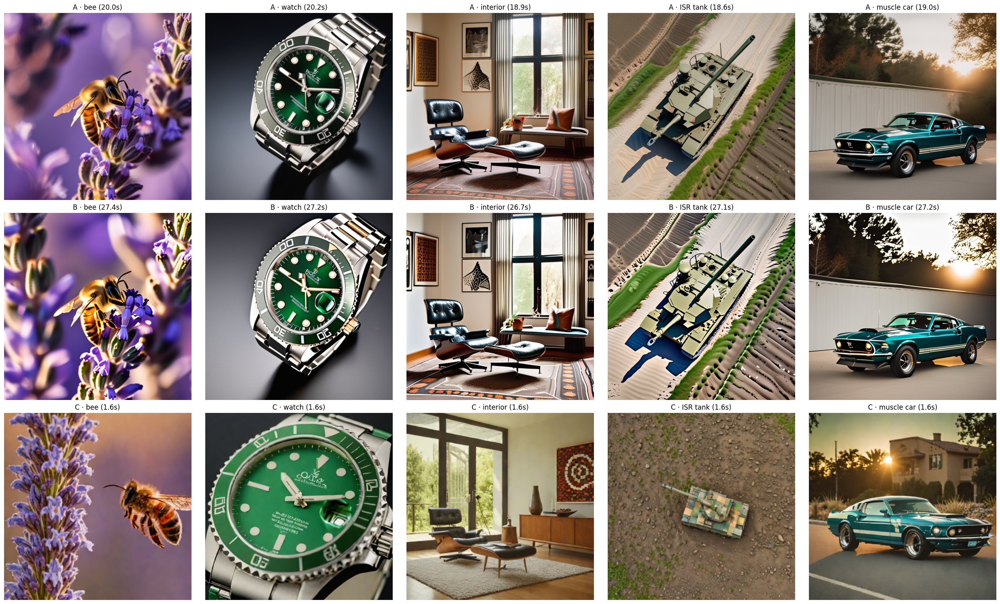

In [6]:
   # Plain 3x5 grid for choosing references and ratings
   fig, axes = plt.subplots(3, 5, figsize=(25, 15))
   for r, cfg in enumerate("ABC"):
       for c in range(5):
           axes[r, c].imshow(images[(cfg, c)])
           axes[r, c].set_title(f"{cfg} · {LABELS[c]} ({times[(cfg, c)]:.1f}s)")
           axes[r, c].axis("off")
   plt.tight_layout(); plt.savefig(f"{OUT}/grid_ABC.png", dpi=100); plt.show()

In [7]:
# Metrics (CLIP via open_clip, LPIPS)
!pip install open-clip-torch lpips --quiet
import sys, gc, time, open_clip, lpips, torch, numpy as np
from PIL import Image
from diffusers import AutoPipelineForText2Image

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
SEED, OUT = 42, "eval"

# Free GPU
sys.last_type = sys.last_value = sys.last_traceback = None
for n in ["pipe", "pipe_cc", "controlnet", "pipe_turbo", "clip_model", "lp"]:
    globals().pop(n, None)
gc.collect(); torch.cuda.empty_cache()
print(f"GPU in use after cleanup: {torch.cuda.memory_allocated()/1e9:.1f} GB")   # want < 1

# Config C: SDXL Turbo, 4 steps, CFG 0, 512px native (only if not already generated)
if any(("C", i) not in images for i in range(5)):
    pipe_turbo = AutoPipelineForText2Image.from_pretrained(
        "stabilityai/sdxl-turbo", torch_dtype=torch.float16, variant="fp16")
    pipe_turbo.to(torch.float16); pipe_turbo.to(DEVICE)
    for i, p in enumerate(PROMPTS):
        t0 = time.time()
        with torch.inference_mode():
            img = pipe_turbo(prompt=p, guidance_scale=0.0, num_inference_steps=4,
                             height=512, width=512,
                             generator=torch.Generator(DEVICE).manual_seed(SEED)).images[0]
        images[("C", i)], times[("C", i)] = img, time.time() - t0
        img.save(f"{OUT}/C_{i}.png"); print(f"C {LABELS[i]:10s} {times[('C', i)]:.1f}s")
    del pipe_turbo; gc.collect(); torch.cuda.empty_cache()

# CLIP score (ViT-B/32, OpenAI weights, QuickGELU to match training
clip_model, _, preprocess = open_clip.create_model_and_transforms('ViT-B-32-quickgelu', pretrained='openai')
tokenizer = open_clip.get_tokenizer('ViT-B-32-quickgelu')
clip_model = clip_model.to(DEVICE).eval()

def clip_score(image: Image.Image, prompt: str) -> float:
    """Compute cosine similarity between image and text prompt using CLIP."""
    img_tensor  = preprocess(image).unsqueeze(0).to(DEVICE)
    text_tensor = tokenizer([prompt]).to(DEVICE)          # truncates at 77 tokens
    with torch.no_grad():
        img_feat  = clip_model.encode_image(img_tensor)
        txt_feat  = clip_model.encode_text(text_tensor)
        img_feat /= img_feat.norm(dim=-1, keepdim=True)
        txt_feat /= txt_feat.norm(dim=-1, keepdim=True)
    return (img_feat @ txt_feat.T).item()

print("CLIP scorer ready")

# LPIPS (perceptual distance; lower = more similar to reference)
lp = lpips.LPIPS(net="alex").to(DEVICE)

def to_lpips(img):
    x = torch.from_numpy(np.array(img.convert("RGB").resize((512, 512)))).permute(2, 0, 1).float()
    return (x / 127.5 - 1).unsqueeze(0).to(DEVICE)       # LPIPS expects [-1, 1]

@torch.no_grad()
def lpips_dist(a, b):
    return lp(to_lpips(a), to_lpips(b)).item()

print("LPIPS ready")

# Per-prompt reference = your highest-quality output. Edit after viewing the grid.
REF = {0: "B", 1: "A", 2: "C", 3: "C", 4: "C"}

metrics = {}
for cfg in "ABC":
    for i, p in enumerate(PROMPTS):
        metrics[(cfg, i)] = {
            "clip": clip_score(images[(cfg, i)], p),
            "lpips": lpips_dist(images[(cfg, i)], images[(REF[i], i)]),
        }
        print(f"{cfg} {LABELS[i]:10s} CLIP {metrics[(cfg, i)]['clip']:.3f}  LPIPS {metrics[(cfg, i)]['lpips']:.3f}")

GPU in use after cleanup: 0.0 GB
CLIP scorer ready
Setting up [LPIPS] perceptual loss: trunk [alex], v[0.1], spatial [off]


/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=AlexNet_Weights.IMAGENET1K_V1`. You can also use `weights=AlexNet_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Loading model from: /usr/local/lib/python3.13/dist-packages/lpips/weights/v0.1/alex.pth
LPIPS ready
A bee        CLIP 0.347  LPIPS 0.363
A watch      CLIP 0.312  LPIPS 0.000
A interior   CLIP 0.299  LPIPS 0.735
A ISR tank   CLIP 0.297  LPIPS 0.657
A muscle car CLIP 0.345  LPIPS 0.714
B bee        CLIP 0.358  LPIPS 0.000
B watch      CLIP 0.331  LPIPS 0.166
B interior   CLIP 0.304  LPIPS 0.750
B ISR tank   CLIP 0.341  LPIPS 0.683
B muscle car CLIP 0.338  LPIPS 0.720
C bee        CLIP 0.354  LPIPS 0.770
C watch      CLIP 0.308  LPIPS 0.702
C interior   CLIP 0.318  LPIPS 0.000
C ISR tank   CLIP 0.338  LPIPS 0.000
C muscle car CLIP 0.336  LPIPS 0.000


In [10]:
# Cell 3: your ratings + evaluation table
!pip install tabulate --quiet
import pandas as pd

# Fill in after viewing the grid: (rating 1-5, one-sentence justification)
RATINGS = {
    ("A", 0): (4, ""), ("A", 1): (3, ""), ("A", 2): (3, ""), ("A", 3): (1, ""), ("A", 4): (3, ""),
    ("B", 0): (3, ""), ("B", 1): (4, ""), ("B", 2): (3, ""), ("B", 3): (1, ""), ("B", 4): (3, ""),
    ("C", 0): (3, ""), ("C", 1): (1, ""), ("C", 2): (4, ""), ("C", 3): (4, ""), ("C", 4): (4, ""),
}
CONFIG_NAMES = {"A": "A: SDXL base", "B": "B: SDXL + Canny 0.7", "C": "C: SDXL Turbo (4 steps)"}

rows = []
for cfg in "ABC":
    for i in range(5):
        rating, note = RATINGS[(cfg, i)]
        rows.append({
            "Config": CONFIG_NAMES[cfg],
            "Prompt": LABELS[i],
            "CLIP Score": round(metrics[(cfg, i)]["clip"], 3),
            "LPIPS": "ref" if REF[i] == cfg else round(metrics[(cfg, i)]["lpips"], 3),
            "Human Rating": rating,
            "Time (s)": round(times[(cfg, i)], 1),
        })
df = pd.DataFrame(rows)
display(df)

# Per-config summary (LPIPS mean excludes reference images)
non_ref = df[df["LPIPS"] != "ref"].assign(LPIPS=lambda d: d["LPIPS"].astype(float))
summary = pd.DataFrame({
    "Mean CLIP": df.groupby("Config")["CLIP Score"].mean().round(3),
    "Mean LPIPS (non-ref)": non_ref.groupby("Config")["LPIPS"].mean().round(3),
    "Mean Rating": pd.to_numeric(df["Human Rating"], errors="coerce").groupby(df["Config"]).mean().round(2),
    "Mean Time (s)": df.groupby("Config")["Time (s)"].mean().round(1),
})
display(summary)

df.to_csv(f"{OUT}/evaluation_table.csv", index=False)
summary.to_csv(f"{OUT}/evaluation_summary.csv")
print(df.to_markdown(index=False))   # paste into write-up

,Config,Prompt,CLIP Score,LPIPS,Human Rating,Time (s)
0,A: SDXL base,bee,0.347,0.363,3,20.0
1,A: SDXL base,watch,0.312,ref,4,20.2
2,A: SDXL base,interior,0.299,0.735,3,18.9
3,A: SDXL base,ISR tank,0.297,0.657,1,18.6
4,A: SDXL base,muscle car,0.345,0.714,3,19.0
5,B: SDXL + Canny 0.7,bee,0.358,ref,4,27.4
6,B: SDXL + Canny 0.7,watch,0.331,0.166,4,27.2
7,B: SDXL + Canny 0.7,interior,0.304,0.75,3,26.7
8,B: SDXL + Canny 0.7,ISR tank,0.341,0.683,1,27.1
9,B: SDXL + Canny 0.7,muscle car,0.338,0.72,3,27.2


,Mean CLIP,Mean LPIPS (non-ref),Mean Rating,Mean Time (s)
Config,,,,
A: SDXL base,0.320,0.617,2.8,19.3
B: SDXL + Canny 0.7,0.334,0.580,3.0,27.1
C: SDXL Turbo (4 steps),0.331,0.736,3.2,1.6


| Config                  | Prompt     |   CLIP Score | LPIPS   |   Human Rating |   Time (s) |
|:------------------------|:-----------|-------------:|:--------|---------------:|-----------:|
| A: SDXL base            | bee        |        0.347 | 0.363   |              3 |       20   |
| A: SDXL base            | watch      |        0.312 | ref     |              4 |       20.2 |
| A: SDXL base            | interior   |        0.299 | 0.735   |              3 |       18.9 |
| A: SDXL base            | ISR tank   |        0.297 | 0.657   |              1 |       18.6 |
| A: SDXL base            | muscle car |        0.345 | 0.714   |              3 |       19   |
| B: SDXL + Canny 0.7     | bee        |        0.358 | ref     |              4 |       27.4 |
| B: SDXL + Canny 0.7     | watch      |        0.331 | 0.166   |              4 |       27.2 |
| B: SDXL + Canny 0.7     | interior   |        0.304 | 0.75    |              3 |       26.7 |
| B: SDXL + Canny 0.7     | ISR tank   |

1. Config A (SDXL base):
- Bee: Overall best, with vibrant colors and apparent anatomical accuracy; slightly matte flower surface appeared more realistic to me than Config B.
- Watch: Overall good structural accuracy, despite hand, text placement, bezel marking, and other errors, though matte bracelet detracted from a jewel-like brilliance that I would have expected from a Swiss luxury sports watch product cattalogue (Config A may have better suited to a worn vintage pilot's watch).
- Interior: Equal quality to my eyes compared to Config B; while I preferred Config A and B's brilliance I found Config C a more realistic interior.
- ISR tank: Unusable due to nonsensical second main gun and its placement.
- Muscle car: Overall good, and I also preferred its reflective brilliance; however, its grill height was just slightly exaggerated, thereby losing in realism if more stereotypically "muscle car."
2. Config B (SDXL + Canny 0.7):
- Bee: I liked the dew-like brilliance, as if photogrpahed early morning. However, I felt the first image's slightly mattish rendering of the flowers' surface communicated a more organic, skin-like structure.
- Watch: While largely equal in quality to Config A, I preferred the catalogue-quality brilliance of Config B, which also also aligned with the product type (luxury sports watch).
- Interior: I liked the sheen as much as Config A, including the sheen coming off the leather Herman Miller-type lounge chair, as if reflecting an afternoon light coming through the window.
- ISR tank: Equally unusable as Config A due to nonsensical second main gun and its placement.
- Muscle car: Quite nice, similar to Config A, including a slightly nicer brilliance; however, similar exaggerated grill-height.
3. Config C SDXL Turbo (4 steps):
- Bee: Great realism but somewhat blurry flower rendering.
- Watch: Lettering so poorly rendered as to be unusable.
- Interior: While lacking the cataglogue-type light reflectivity, with somewhat muted or dusty colors, I preferred the realism of this interior.
- ISR tank: Default winner as the only properly rendered trank, including interestingly rendered camoflage; however, I could not prompt the model to render anti-drone caging (perhaps due to minimal training examples as such defensive measures are relatively new battlefield developments).
- Muscle car: I prefered this vehicle as proportions far more accurately rendered.